# Statistical analysis for regression models

## Environment

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

## Loading result dataframes

In [2]:
# Models dictionary for regression
models_dict = {
    "Linear Regression": pd.read_csv("output/linear_regression_regression_results.csv"),
    "Ridge": pd.read_csv("output/ridge_regression_results.csv"),
    "Lasso": pd.read_csv("output/lasso_regression_results.csv"),
    "Random Forest": pd.read_csv("output/random_forest_regression_results.csv"),
    "KNN": pd.read_csv("output/knn_regression_results.csv"),
    "Decision Tree": pd.read_csv("output/decision_tree_regression_results.csv"),
    "XGBoost": pd.read_csv("output/xgboost_regression_results.csv"),
}

# Regression metrics
metrics = [
    "mae",
    "rmse", 
    "r2",
]

# Number of runs
n = models_dict["Random Forest"].shape[0]

# Significance level
alpha = 0.05

# t-quantile for the given alpha and degrees of freedom
t_quantile = stats.t.ppf(1 - alpha / 2, df=n - 1)

## Confidence intervals visualization

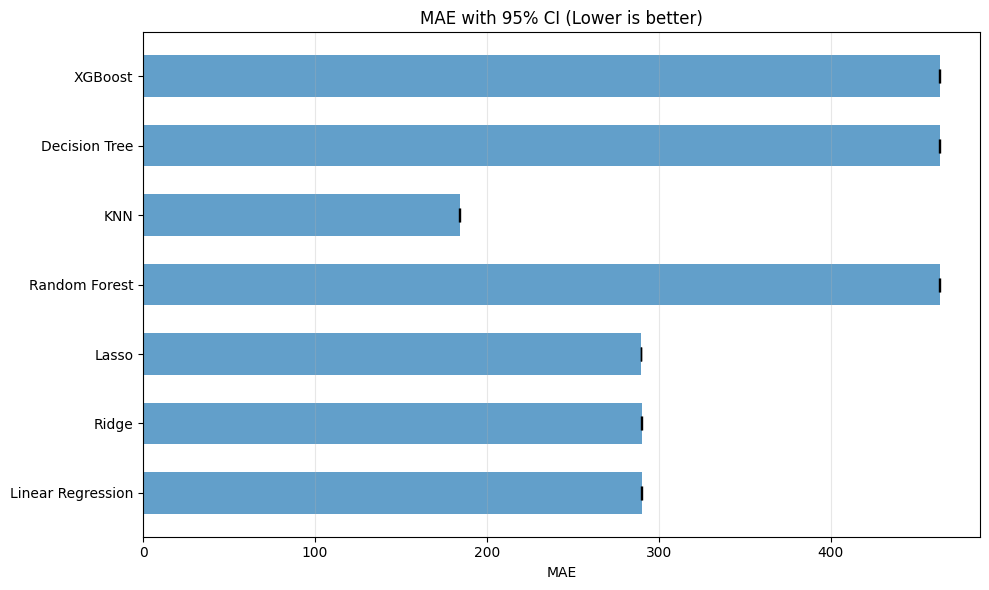

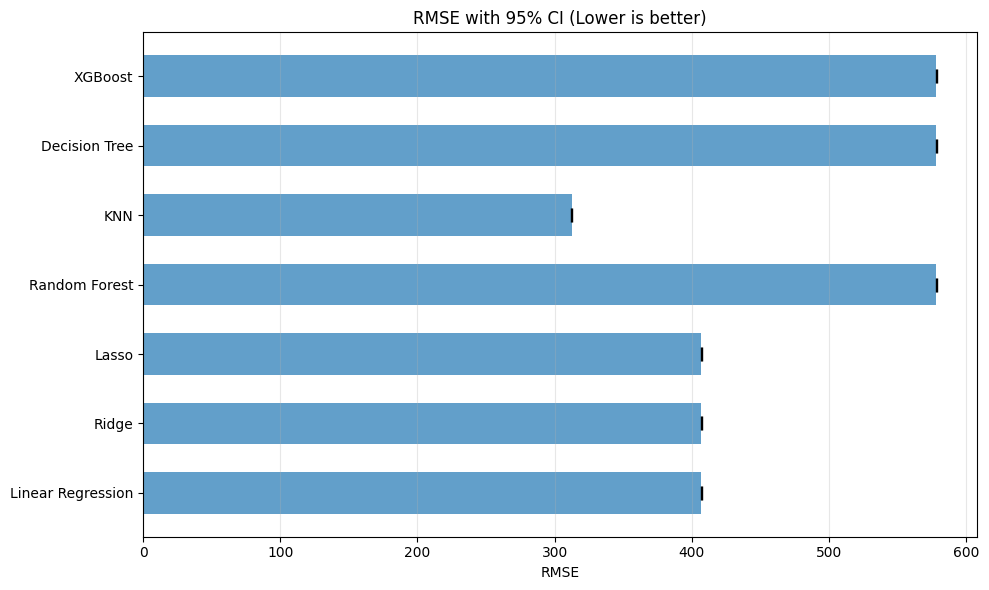

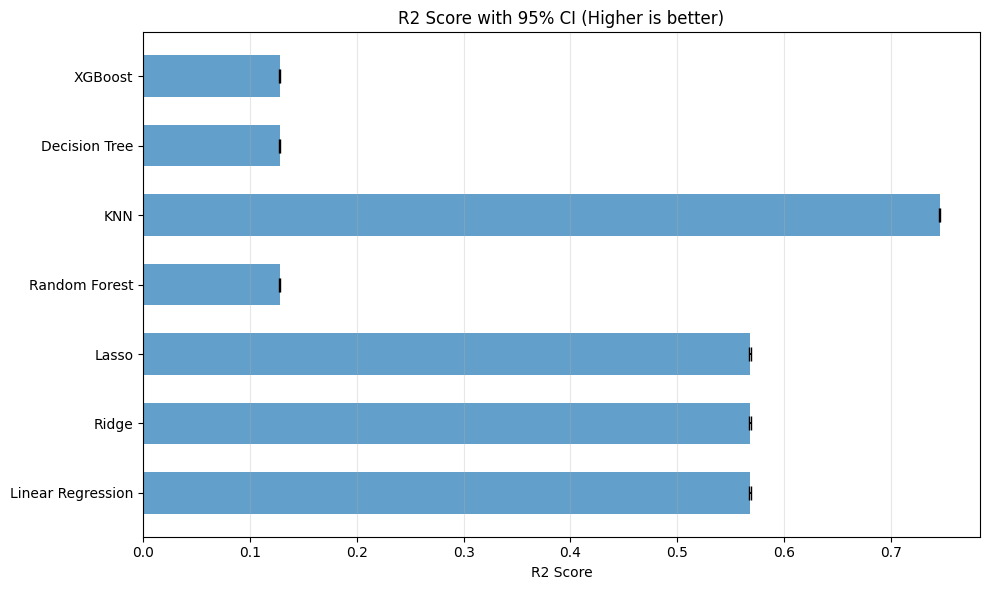

In [3]:
for metric in metrics:
    means = [models_dict[m][metric].mean() for m in models_dict.keys()]
    stds = [models_dict[m][metric].std() for m in models_dict.keys()]

    ci_lower = np.array(means) - t_quantile * (np.array(stds) / np.sqrt(n))
    ci_upper = np.array(means) + t_quantile * (np.array(stds) / np.sqrt(n))

    plt.figure(figsize=(10, 6))
    plt.barh(
        list(models_dict.keys()),
        means,
        xerr=[np.array(means) - ci_lower, ci_upper - np.array(means)],
        capsize=5,
        height=0.6,
        alpha=0.7
    )
    
    # Add metric-specific formatting
    if metric == "r2":
        plt.xlabel(f"{metric.upper()} Score")
        plt.title(f"{metric.upper()} Score with 95% CI (Higher is better)")
    else:
        plt.xlabel(f"{metric.upper()}")
        plt.title(f"{metric.upper()} with 95% CI (Lower is better)")
    
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

## Summary statistics table

In [4]:
# Initialize summary table
rows = []

# Create a detailed summary table
for model_name, df in models_dict.items():
    for metric in metrics:
        mean = df[metric].mean()
        std = df[metric].std(ddof=1)
        ci_lower = mean - t_quantile * (std / np.sqrt(n))
        ci_upper = mean + t_quantile * (std / np.sqrt(n))
        ci95 = f"[{ci_lower:.4f}, {ci_upper:.4f}]"

        rows.append(
            {
                "Model": model_name,
                "Metric": metric.upper(),
                "Mean": f"{mean:.4f}",
                "Std": f"{std:.4f}",
                "CI_95%": ci95,
            }
        )

summary_multi = pd.DataFrame(rows)

# Set multi-index for better visualization
summary_multi = summary_multi.set_index(["Model", "Metric"])

print("Statistical Summary of Regression Models Performance")
print("=" * 55)
print(summary_multi)

Statistical Summary of Regression Models Performance
                              Mean     Std                CI_95%
Model             Metric                                        
Linear Regression MAE     290.0054  0.6654  [289.7569, 290.2539]
                  RMSE    406.9765  1.2737  [406.5009, 407.4521]
                  R2        0.5682  0.0020      [0.5675, 0.5690]
Ridge             MAE     290.0057  0.6654  [289.7573, 290.2542]
                  RMSE    406.9765  1.2736  [406.5009, 407.4521]
                  R2        0.5682  0.0020      [0.5675, 0.5690]
Lasso             MAE     289.6559  0.6697  [289.4058, 289.9060]
                  RMSE    407.0116  1.2787  [406.5342, 407.4891]
                  R2        0.5682  0.0021      [0.5674, 0.5689]
Random Forest     MAE     463.3845  0.6719  [463.1336, 463.6354]
                  RMSE    578.4173  1.0138  [578.0387, 578.7958]
                  R2        0.1278  0.0015      [0.1273, 0.1284]
KNN               MAE     184.0694  0

## Model ranking by performance

In [5]:
# Create ranking tables for each metric
print("Model Rankings by Performance")
print("=" * 30)

for metric in metrics:
    ranking_data = []
    
    for model_name, df in models_dict.items():
        mean_score = df[metric].mean()
        std_score = df[metric].std(ddof=1)
        ranking_data.append({
            "Model": model_name,
            "Mean": mean_score,
            "Std": std_score
        })
    
    ranking_df = pd.DataFrame(ranking_data)
    
    # Sort by performance (ascending for MAE/RMSE, descending for R2)
    if metric == "r2":
        ranking_df = ranking_df.sort_values("Mean", ascending=False)
        print(f"\n{metric.upper()} Ranking (Higher is better):")
    else:
        ranking_df = ranking_df.sort_values("Mean", ascending=True)
        print(f"\n{metric.upper()} Ranking (Lower is better):")
    
    ranking_df["Rank"] = range(1, len(ranking_df) + 1)
    ranking_df = ranking_df[["Rank", "Model", "Mean", "Std"]]
    ranking_df["Mean"] = ranking_df["Mean"].round(4)
    ranking_df["Std"] = ranking_df["Std"].round(4)
    
    print(ranking_df.to_string(index=False))

Model Rankings by Performance

MAE Ranking (Lower is better):
 Rank             Model     Mean    Std
    1               KNN 184.0694 0.6021
    2             Lasso 289.6559 0.6697
    3 Linear Regression 290.0054 0.6654
    4             Ridge 290.0057 0.6654
    5     Decision Tree 463.3843 0.6774
    6     Random Forest 463.3845 0.6719
    7           XGBoost 463.3942 0.6783

RMSE Ranking (Lower is better):
 Rank             Model     Mean    Std
    1               KNN 312.3759 1.0303
    2             Ridge 406.9765 1.2736
    3 Linear Regression 406.9765 1.2737
    4             Lasso 407.0116 1.2787
    5     Random Forest 578.4173 1.0138
    6     Decision Tree 578.4173 1.0137
    7           XGBoost 578.4175 1.0135

R2 Ranking (Higher is better):
 Rank             Model   Mean    Std
    1               KNN 0.7456 0.0014
    2             Ridge 0.5682 0.0020
    3 Linear Regression 0.5682 0.0020
    4             Lasso 0.5682 0.0021
    5     Random Forest 0.1278 0.0015
    6

## Statistical significance tests

In [6]:
# Perform pairwise t-tests to check for statistical significance
from itertools import combinations

print("Statistical Significance Tests (Paired t-tests)")
print("=" * 50)

for metric in metrics:
    print(f"\n{metric.upper()} - Pairwise comparisons:")
    print("-" * 30)
    
    model_names = list(models_dict.keys())
    significant_pairs = []
    
    for model1, model2 in combinations(model_names, 2):
        # Get the metric values for both models
        values1 = models_dict[model1][metric].values
        values2 = models_dict[model2][metric].values
        
        # Perform paired t-test
        t_stat, p_value = stats.ttest_rel(values1, values2)
        
        # Check if significant
        is_significant = p_value < alpha
        
        if is_significant:
            mean1 = np.mean(values1)
            mean2 = np.mean(values2)
            
            if metric == "r2":
                better_model = model1 if mean1 > mean2 else model2
            else:  # For MAE and RMSE, lower is better
                better_model = model1 if mean1 < mean2 else model2
            
            significant_pairs.append({
                'Comparison': f"{model1} vs {model2}",
                'p_value': p_value,
                'Better_model': better_model,
                't_statistic': t_stat
            })
    
    if significant_pairs:
        sig_df = pd.DataFrame(significant_pairs)
        sig_df['p_value'] = sig_df['p_value'].round(6)
        sig_df['t_statistic'] = sig_df['t_statistic'].round(4)
        print(sig_df.to_string(index=False))
    else:
        print("No statistically significant differences found.")

Statistical Significance Tests (Paired t-tests)

MAE - Pairwise comparisons:
------------------------------
                        Comparison  p_value      Better_model  t_statistic
        Linear Regression vs Ridge      0.0 Linear Regression     -12.2494
        Linear Regression vs Lasso      0.0             Lasso     151.0021
Linear Regression vs Random Forest      0.0 Linear Regression   -1339.5359
          Linear Regression vs KNN      0.0               KNN    1138.1565
Linear Regression vs Decision Tree      0.0 Linear Regression   -1333.3987
      Linear Regression vs XGBoost      0.0 Linear Regression   -1325.6498
                    Ridge vs Lasso      0.0             Lasso     151.8806
            Ridge vs Random Forest      0.0             Ridge   -1339.5670
                      Ridge vs KNN      0.0               KNN    1138.1506
            Ridge vs Decision Tree      0.0             Ridge   -1333.4283
                  Ridge vs XGBoost      0.0             Ridge   -13

## Best model recommendation

In [7]:
# Provide a comprehensive recommendation
print("Model Recommendation Summary")
print("=" * 30)

# Calculate overall performance scores (normalized)
model_scores = {}

for model_name in models_dict.keys():
    scores = {}
    
    # Get performance for each metric
    mae_mean = models_dict[model_name]['mae'].mean()
    rmse_mean = models_dict[model_name]['rmse'].mean()
    r2_mean = models_dict[model_name]['r2'].mean()
    
    scores['mae'] = mae_mean
    scores['rmse'] = rmse_mean
    scores['r2'] = r2_mean
    
    model_scores[model_name] = scores

# Find best model for each metric
best_mae = min(model_scores.items(), key=lambda x: x[1]['mae'])
best_rmse = min(model_scores.items(), key=lambda x: x[1]['rmse'])
best_r2 = max(model_scores.items(), key=lambda x: x[1]['r2'])

print(f"Best MAE (lowest): {best_mae[0]} ({best_mae[1]['mae']:.4f})")
print(f"Best RMSE (lowest): {best_rmse[0]} ({best_rmse[1]['rmse']:.4f})")
print(f"Best R² (highest): {best_r2[0]} ({best_r2[1]['r2']:.4f})")

# Count how many times each model is best
best_counts = {}
for model in models_dict.keys():
    count = 0
    if model == best_mae[0]: count += 1
    if model == best_rmse[0]: count += 1
    if model == best_r2[0]: count += 1
    best_counts[model] = count

# Find overall best model
overall_best = max(best_counts.items(), key=lambda x: x[1])

print(f"\nOverall recommended model: {overall_best[0]}")
print(f"(Best in {overall_best[1]} out of 3 metrics)")

# Show detailed performance of recommended model
recommended_model = overall_best[0]
print(f"\nDetailed performance of {recommended_model}:")
for metric in metrics:
    mean_val = models_dict[recommended_model][metric].mean()
    std_val = models_dict[recommended_model][metric].std()
    print(f"  {metric.upper()}: {mean_val:.4f} ± {std_val:.4f}")

Model Recommendation Summary
Best MAE (lowest): KNN (184.0694)
Best RMSE (lowest): KNN (312.3759)
Best R² (highest): KNN (0.7456)

Overall recommended model: KNN
(Best in 3 out of 3 metrics)

Detailed performance of KNN:
  MAE: 184.0694 ± 0.6021
  RMSE: 312.3759 ± 1.0303
  R2: 0.7456 ± 0.0014
